# Predicting Loan-Application Abandonment with Markov Chains and HMMs
**Data:** BPI Challenge 2017 (real loan applications from a Dutch financial institution)
**Question:** Given the first *k* events of an application, how likely is it to end in **cancellation (abandonment)** rather than **completion**?

**Pipeline:** Import → Load → View → EDA → Split → Train → Predict → Accuracy → Final graphs → Conclusion

**Models**
1. **Absorbing Markov chain**: `P(eventual abandon | current state)`
2. **Class-conditional Markov chains**: one chain per outcome, compared by likelihood ratio
3. **Hidden Markov Models**: one HMM per outcome, compared by likelihood ratio (forward algorithm)
4. **Baseline**: logistic regression on prefix length only (to check the models add something)

> **Data note.** Download the log from the 4TU repository (DOI `10.4121/uuid:5f3067df-f10b-45da-b98b-86ae4c7a310b`) and put it next to this notebook as `BPI Challenge 2017.xes.gz`.
> If the file is missing, the notebook generates a **synthetic demo log** so every cell still runs. Synthetic numbers are *not* research results.

## 1. Import

In [1]:
# !pip install hmmlearn scikit-learn pandas matplotlib numpy   # uncomment if needed
import gzip, os, warnings
import xml.etree.ElementTree as ET
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hmmlearn.hmm import CategoricalHMM
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             f1_score, accuracy_score, balanced_accuracy_score,
                             precision_score, recall_score, confusion_matrix)

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42
rng = np.random.default_rng(SEED)

# ---- Configuration ----
XES_PATH = "bpi_2017_cleaned.csv"
ALLOW_SYNTHETIC_FALLBACK = False
KEEP_PREFIXES = ("A_", "O_")                         # customer/application-facing events (W_* are bank work items)
TERMINAL = {"A_Cancelled": 1, "A_Pending": 0}        # 1 = abandon, 0 = complete (A_Denied is excluded)
EXCLUDE_OUTCOMES = {"A_Denied"}
MIN_PREFIX = 2          # shortest prefix we try to predict from
GAP = 2                 # leave >= GAP events unseen before the end, so we predict instead of detect the ending
N_HIDDEN = 5            # HMM hidden states
MAX_HMM_SEQS = 6000     # cap per class for HMM training speed

## 2. Load

In [2]:
import zipfile

def read_xes(path):
    """XES reader that detects gzip / zip / plain XML from the file's first bytes."""
    with open(path, "rb") as fh:
        head = fh.read(200)
    if head[:2] == b"\x1f\x8b":                       # gzip
        f = gzip.open(path, "rb")
    elif head[:2] == b"PK":                           # zip
        z = zipfile.ZipFile(path)
        f = z.open(next(n for n in z.namelist() if n.lower().endswith(".xes")))
    elif b"<html" in head.lower() or b"<!doctype html" in head.lower():
        raise ValueError("This file is a web page, not the dataset. Re-download it from the 4TU page.")
    else:                                             # plain XML
        f = open(path, "rb")

    rows = []
    with f:
        for _, el in ET.iterparse(f, events=("end",)):
            if el.tag.split("}")[-1] != "trace":
                continue
            cid = None
            for c in el:
                t = c.tag.split("}")[-1]
                if t == "string" and c.get("key") == "concept:name":
                    cid = c.get("value")
                elif t == "event":
                    d = {x.get("key"): x.get("value") for x in c}
                    rows.append((cid, d.get("concept:name"), d.get("time:timestamp"), d.get("lifecycle:transition")))
            el.clear()
    return pd.DataFrame(rows, columns=["case", "event", "ts", "lifecycle"])

def make_synthetic(n_cases=6000):
    """Synthetic stand-in with BPI17-like event names. NOT real data."""
    S = ["A_Create Application", "A_Submitted", "A_Concept", "A_Accepted", "O_Create Offer", "O_Created",
         "O_Sent (mail and online)", "A_Complete", "A_Validating", "O_Returned", "A_Incomplete", "O_Accepted"]
    ok  = {"A_Create Application": ["A_Submitted"], "A_Submitted": ["A_Concept"], "A_Concept": ["A_Accepted"],
           "A_Accepted": ["O_Create Offer"], "O_Create Offer": ["O_Created"], "O_Created": ["O_Sent (mail and online)"],
           "O_Sent (mail and online)": ["O_Returned", "O_Sent (mail and online)"], "O_Returned": ["A_Validating"],
           "A_Validating": ["A_Incomplete", "O_Accepted"], "A_Incomplete": ["A_Validating"], "O_Accepted": ["A_Complete"]}
    rows = []
    t0 = pd.Timestamp("2016-01-01", tz="UTC")
    for i in range(n_cases):
        wavering = rng.random() < 0.4
        ev, cur = ["A_Create Application"], "A_Create Application"
        while cur in ok and len(ev) < 40:
            opts = ok[cur]
            if wavering and cur in ("O_Sent (mail and online)", "A_Validating") and rng.random() < 0.55:
                nxt = cur if cur == "O_Sent (mail and online)" else "A_Incomplete"
            else:
                nxt = opts[rng.integers(len(opts))]
            if wavering and rng.random() < 0.10 and len(ev) > 4:
                break
            ev.append(nxt); cur = nxt
        if wavering and rng.random() < 0.85:   outcome = "A_Cancelled"
        elif rng.random() < 0.08:              outcome = "A_Denied"
        else:                                  outcome = "A_Pending"
        ev.append(outcome)
        t = t0 + pd.Timedelta(days=float(rng.uniform(0, 365)))
        for e in ev:
            t += pd.Timedelta(hours=float(rng.exponential(10)))
            rows.append((f"Application_{i}", e, t.isoformat(), "complete"))
    return pd.DataFrame(rows, columns=["case", "event", "ts", "lifecycle"])


def read_csv_log(path):
    """Read a CSV event log; auto-detect which columns are case id / event / timestamp / lifecycle."""
    df = pd.read_csv(path, low_memory=False)
    norm = {c: c.strip().lower().replace(" ", "").replace("_", "").replace(":", "").replace(".", "") for c in df.columns}
    def find(cands):
        for cand in cands:
            for c, n in norm.items():
                if n == cand:
                    return c
        return None
    col = {
        "case": find(["caseconceptname", "caseid", "case", "caseidentifier", "applicationid", "id", "traceid"]),
        "event": find(["conceptname", "event", "activity", "eventname", "action", "activityname"]),
        "ts": find(["timetimestamp", "timestamp", "time", "datetime", "eventtime", "starttimestamp", "date"]),
        "lifecycle": find(["lifecycletransition", "lifecycle", "transition"]),
    }
    missing = [k for k in ("case", "event", "ts") if col[k] is None]
    if missing:
        raise ValueError(f"Could not detect columns {missing}. Your CSV columns are: {list(df.columns)}. "
                         "Set them by hand in the dict 'col' above.")
    out = pd.DataFrame({"case": df[col["case"]].astype(str), "event": df[col["event"]].astype(str), "ts": df[col["ts"]]})
    out["lifecycle"] = df[col["lifecycle"]] if col["lifecycle"] else "complete"
    print("Column mapping used:", {k: v for k, v in col.items()})
    return out


def load_log(path):
    low = path.lower()
    if low.endswith((".csv", ".csv.gz", ".csv.zip", ".txt")):
        return read_csv_log(path)
    return read_xes(path)


USING_SYNTHETIC = False
if os.path.exists(XES_PATH):
    raw = load_log(XES_PATH)
    print(f"Loaded real BPI 2017 log: {len(raw):,} events")
elif ALLOW_SYNTHETIC_FALLBACK:
    USING_SYNTHETIC = True
    raw = make_synthetic()
    print("WARNING: BPI17 file not found -> using SYNTHETIC demo data. Do not report these numbers as results.")
else:
    raise FileNotFoundError(f"File not found: '{os.path.abspath(XES_PATH)}'. Put it in this folder or use a full path.")


Column mapping used: {'case': 'case:concept:name', 'event': 'concept:name', 'ts': 'time:timestamp', 'lifecycle': 'lifecycle:transition'}
Loaded real BPI 2017 log: 1,202,267 events


## 3. View

In [3]:
try:
    raw["ts"] = pd.to_datetime(raw["ts"], utc=True, format="ISO8601")
except (ValueError, TypeError):
    raw["ts"] = pd.to_datetime(raw["ts"], utc=True, format="mixed", dayfirst=True)
assert raw["event"].str.startswith(("A_", "O_")).any(), (
    "No events start with A_ or O_. Check the event column; sample values: " + str(raw["event"].unique()[:10]))
print("Shape:", raw.shape)
display(raw.head(10))
print("\nColumn types:"); print(raw.dtypes)
print("\nMissing values:"); print(raw.isna().sum())

Shape: (1202267, 4)


,case,event,ts,lifecycle
0,Application_652823628,A_Create Application,2016-01-01 09:51:15.304000+00:00,complete
1,Application_652823628,A_Submitted,2016-01-01 09:51:15.352000+00:00,complete
2,Application_652823628,W_Handle leads,2016-01-01 09:51:15.774000+00:00,schedule
3,Application_652823628,W_Handle leads,2016-01-01 09:52:36.392000+00:00,withdraw
4,Application_652823628,W_Complete application,2016-01-01 09:52:36.403000+00:00,schedule
5,Application_652823628,A_Concept,2016-01-01 09:52:36.413000+00:00,complete
6,Application_652823628,W_Complete application,2016-01-02 10:45:22.429000+00:00,start
7,Application_652823628,W_Complete application,2016-01-02 10:49:28.816000+00:00,suspend
8,Application_652823628,A_Accepted,2016-01-02 11:23:04.299000+00:00,complete
9,Application_652823628,O_Create Offer,2016-01-02 11:29:03.994000+00:00,complete



Column types:
case                      object
event                     object
ts           datetime64[ns, UTC]
lifecycle                 object
dtype: object

Missing values:
case         0
event        0
ts           0
lifecycle    0
dtype: int64


## 4. EDA
Keep only application/offer events, order each case by time, cut the trace at the **first terminal event**
(so the outcome is never visible to the model), then label it.

In [4]:
df = raw[raw["event"].str.startswith(KEEP_PREFIXES)]
df = df[df["lifecycle"].isin(["complete"]) | df["lifecycle"].isna()]
df = df.sort_values(["case", "ts"], kind="mergesort")

cases = []
for cid, g in df.groupby("case", sort=False):
    ev = g["event"].tolist()
    term = next((i for i, e in enumerate(ev) if e in TERMINAL or e in EXCLUDE_OUTCOMES), None)
    if term is None or ev[term] in EXCLUDE_OUTCOMES:
        continue                                    # unfinished or denied -> drop
    seq = ev[:term]
    if len(seq) >= 1:
        cases.append((cid, seq, TERMINAL[ev[term]], g["ts"].iloc[0]))

cdf = pd.DataFrame(cases, columns=["case", "seq", "y", "start"]).sort_values("start").reset_index(drop=True)
cdf["len"] = cdf["seq"].str.len()
print(f"Usable cases: {len(cdf):,}  |  abandonment rate: {cdf['y'].mean():.1%}")
display(cdf["len"].describe().to_frame().T)

Usable cases: 27,659  |  abandonment rate: 37.7%


,count,mean,std,min,25%,50%,75%,max
len,27659.0,12.077913,3.959915,5.0,8.0,12.0,14.0,45.0


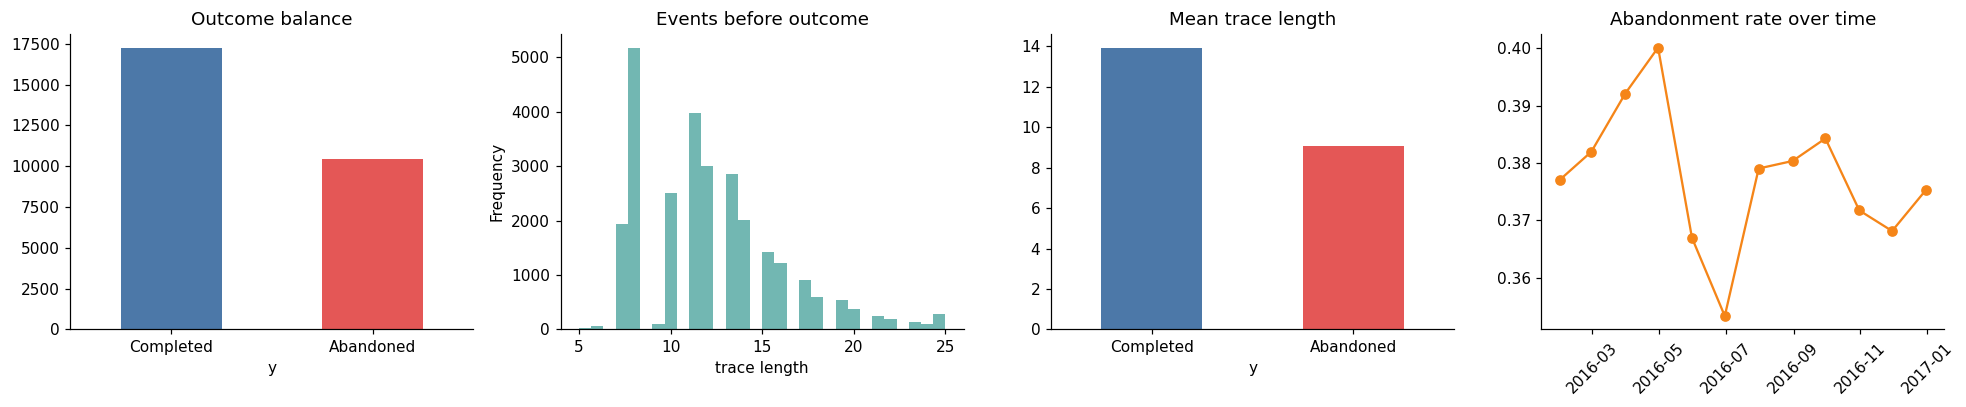

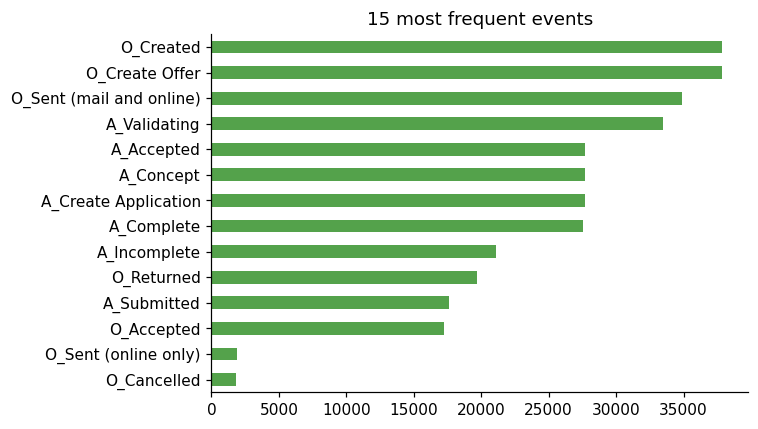

Distinct variants: 2,179  (top-10 cover 62.3% of cases)


In [5]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))

cdf["y"].map({0: "Completed", 1: "Abandoned"}).value_counts().plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"], rot=0)
ax[0].set_title("Outcome balance")

cdf["len"].clip(upper=cdf["len"].quantile(0.99)).plot.hist(bins=30, ax=ax[1], color="#72B7B2")
ax[1].set_title("Events before outcome"); ax[1].set_xlabel("trace length")

cdf.groupby("y")["len"].mean().rename({0: "Completed", 1: "Abandoned"}).plot.bar(ax=ax[2], color=["#4C78A8", "#E45756"], rot=0)
ax[2].set_title("Mean trace length")

m = cdf.set_index("start")["y"].resample("ME").agg(["mean", "size"])
m = m[m["size"] >= 20]
ax[3].plot(m.index, m["mean"], marker="o", color="#F58518")
ax[3].set_title("Abandonment rate over time"); ax[3].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

freq = Counter(e for s in cdf["seq"] for e in s)
pd.Series(freq).sort_values().tail(15).plot.barh(figsize=(7, 4), color="#54A24B", title="15 most frequent events")
plt.tight_layout(); plt.show()

variants = cdf["seq"].map(tuple).value_counts()
print(f"Distinct variants: {len(variants):,}  (top-10 cover {variants.head(10).sum() / len(cdf):.1%} of cases)")

## 5. Split
**Chronological** 60 / 20 / 20 (train / validation / test), because shuffling would leak future behaviour into training.
Validation is used only to choose each model's decision threshold.

In [6]:
n = len(cdf); a, b = int(0.6 * n), int(0.8 * n)
train, val, test = cdf.iloc[:a], cdf.iloc[a:b], cdf.iloc[b:]
for name, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s} {len(d):6,} cases | abandon {d['y'].mean():.1%} | {d['start'].min().date()} -> {d['start'].max().date()}")

# vocabulary from TRAIN only. id 0 = START, id 1 = UNK (unseen), then events
vocab = {"<START>": 0, "<UNK>": 1}
for e in sorted({e for s in train["seq"] for e in s}):
    vocab[e] = len(vocab)
inv = {v: k for k, v in vocab.items()}
V = len(vocab)
enc = lambda seq: np.array([vocab.get(e, 1) for e in seq], dtype=int)
print("State space size:", V)

train 16,595 cases | abandon 37.8% | 2016-01-01 -> 2016-08-15
val    5,532 cases | abandon 38.4% | 2016-08-15 -> 2016-10-17
test   5,532 cases | abandon 36.9% | 2016-10-17 -> 2016-12-31
State space size: 16


## 6. Train
All three Markov-type models are fitted on **training cases only**, using the full pre-outcome sequence.
Laplace smoothing handles rare transitions.

In [7]:
ALPHA = 0.5
def fit_absorbing(df_):
    cnt = np.zeros((V, V + 2))                      # cols: V states + [COMPLETE, ABANDON]
    for seq, y in zip(df_["seq"], df_["y"]):
        s = np.r_[0, enc(seq)]
        np.add.at(cnt, (s[:-1], s[1:]), 1)
        cnt[s[-1], V + y] += 1
    mask = np.ones_like(cnt); mask[:, 0] = 0        # nothing transitions INTO <START>
    P = cnt + ALPHA * mask; P /= P.sum(1, keepdims=True)
    Q, R = P[:, :V], P[:, V:]
    B = np.linalg.solve(np.eye(V) - Q, R)           # absorption probabilities
    return P, R[:, 1], B[:, 1]                      # full P, P(abandon next), P(eventually abandon)

def fit_class_chain(df_):
    cnt = np.zeros((V, V))
    for seq in df_["seq"]:
        s = np.r_[0, enc(seq)]
        np.add.at(cnt, (s[:-1], s[1:]), 1)
    mask = np.ones_like(cnt); mask[:, 0] = 0
    T = cnt + ALPHA * mask
    return T / T.sum(1, keepdims=True)

def fit_hmm(df_, seed):
    idx = rng.permutation(len(df_))[:MAX_HMM_SEQS]
    xs = [enc(df_["seq"].iloc[i]) for i in idx]
    X = np.concatenate(xs).reshape(-1, 1); lens = [len(x) for x in xs]
    m = CategoricalHMM(n_components=N_HIDDEN, n_features=V, n_iter=60, tol=1e-3, random_state=seed, init_params="ste")
    m.fit(X, lens)
    m.emissionprob_ = (m.emissionprob_ + 1e-6) / (m.emissionprob_ + 1e-6).sum(1, keepdims=True)   # avoid log(0)
    return m

P_abs, p_next, p_ev = fit_absorbing(train)
chains = {c: fit_class_chain(train[train["y"] == c]) for c in (0, 1)}
hmms = {c: fit_hmm(train[train["y"] == c], SEED + c) for c in (0, 1)}
log_prior = np.log(train["y"].mean() / (1 - train["y"].mean()))

# trivial baseline: prefix length only
def prefix_table(df_):
    r = [(k, y) for seq, y in zip(df_["seq"], df_["y"]) for k in range(MIN_PREFIX, len(seq) - GAP + 1)]
    return np.array(r)
tr = prefix_table(train)
baseline = LogisticRegression().fit(np.log1p(tr[:, [0]]), tr[:, 1])
print(f"Fitted: absorbing chain, 2 class chains, 2 HMMs ({N_HIDDEN} hidden states), baseline  |  train prefixes: {len(tr):,}")

Fitted: absorbing chain, 2 class chains, 2 HMMs (5 hidden states), baseline  |  train prefixes: 151,154


## 7. Predict
Each model scores every prefix of every validation/test case, leaving at least `GAP` events unseen.
For the class-conditional models the score is the posterior log-odds
`log P(prefix | abandon) − log P(prefix | complete) + log prior-odds`.
HMM likelihoods use the **scaled forward algorithm**, so one pass gives the score for every prefix length.

In [8]:
sigmoid = lambda z: 1 / (1 + np.exp(-np.clip(z, -30, 30)))

def hmm_prefix_ll(m, x):
    pi, A, B = m.startprob_, m.transmat_, m.emissionprob_
    alpha = pi * B[:, x[0]]; c = alpha.sum(); alpha = alpha / c
    ll = [np.log(c)]
    for o in x[1:]:
        alpha = (alpha @ A) * B[:, o]; c = alpha.sum(); alpha = alpha / c
        ll.append(ll[-1] + np.log(c))
    return np.array(ll)

def score_cases(df_):
    out = []
    for cid, seq, y in zip(df_["case"], df_["seq"], df_["y"]):
        x = enc(seq); n_ = len(x)
        ks = np.arange(MIN_PREFIX, n_ - GAP + 1)
        if len(ks) == 0: continue
        s = np.r_[0, x]; i = ks - 1
        cc = {c: np.cumsum(np.log(chains[c][s[:-1], s[1:]])) for c in (0, 1)}
        hh = {c: hmm_prefix_ll(hmms[c], x) for c in (0, 1)}
        out.append(pd.DataFrame({
            "case": cid, "k": ks, "y": y, "last_event": [inv[v] for v in x[i]],
            "Absorbing Markov": p_ev[x[i]],
            "Class-cond. Markov": sigmoid(cc[1][i] - cc[0][i] + log_prior),
            "HMM": sigmoid(hh[1][i] - hh[0][i] + log_prior),
            "Baseline (length)": baseline.predict_proba(np.log1p(ks.reshape(-1, 1)))[:, 1]}))
    return pd.concat(out, ignore_index=True)

val_s, test_s = score_cases(val), score_cases(test)
MODELS = ["Absorbing Markov", "Class-cond. Markov", "HMM", "Baseline (length)"]
print(f"Scored prefixes  val: {len(val_s):,}  test: {len(test_s):,}")
display(test_s.head())

Scored prefixes  val: 49,168  test: 50,764


,case,k,y,last_event,Absorbing Markov,Class-cond. Markov,HMM,Baseline (length)
0,Application_1037771791,2,0,A_Submitted,0.378029,0.431763,0.815378,0.475214
1,Application_1037771791,3,0,A_Concept,0.378080,0.431673,0.979476,0.387466
2,Application_1037771791,4,0,A_Accepted,0.378113,0.431566,0.980999,0.323825
3,Application_1037771791,5,0,O_Create Offer,0.378146,0.431458,0.950840,0.276156
4,Application_1037771791,6,0,O_Created,0.378169,0.431374,0.878729,0.239423


In [9]:
# Example: step-by-step risk for one test application
ex = test[test["seq"].str.len() >= 8].iloc[0]
tmp = test_s[test_s["case"] == ex["case"]][["k", "last_event"] + MODELS[:3]].round(3)
print(f"Case {ex['case']} -> actual outcome: {'ABANDONED' if ex['y'] else 'COMPLETED'}")
display(tmp.reset_index(drop=True))

def predict_abandonment(events, model="HMM", threshold=0.5):
    """Risk of abandonment for a live prefix of events (HMM or Markov)."""
    x = enc(events); s = np.r_[0, x]
    if model == "HMM":
        z = hmm_prefix_ll(hmms[1], x)[-1] - hmm_prefix_ll(hmms[0], x)[-1] + log_prior
        p = float(sigmoid(z))
    else:
        p = float(p_ev[x[-1]])
    return {"risk": round(p, 3), "flag_for_followup": p >= threshold}

print(predict_abandonment(ex["seq"][:5]))

Case Application_1037771791 -> actual outcome: COMPLETED


,k,last_event,Absorbing Markov,Class-cond. Markov,HMM
0,2,A_Submitted,0.378,0.432,0.815
1,3,A_Concept,0.378,0.432,0.979
2,4,A_Accepted,0.378,0.432,0.981
3,5,O_Create Offer,0.378,0.431,0.951
4,6,O_Created,0.378,0.431,0.879
5,7,O_Sent (mail and online),0.382,0.432,0.880
6,8,A_Complete,0.388,0.459,0.836
7,9,O_Create Offer,0.378,0.766,0.949
8,10,O_Created,0.378,0.766,0.875
9,11,O_Sent (mail and online),0.382,0.767,0.876


{'risk': 0.951, 'flag_for_followup': True}


## 8. Accuracy
Thresholds are tuned on **validation** (best F1) and applied unchanged to **test**.

In [10]:
def best_threshold(y, p):
    ts = np.linspace(0.05, 0.95, 91)
    return ts[np.argmax([f1_score(y, p >= t) for t in ts])]

rows, thr = [], {}
for m in MODELS:
    thr[m] = best_threshold(val_s["y"], val_s[m])
    pred = (test_s[m] >= thr[m]).astype(int)
    rows.append({"Model": m, "Threshold": round(thr[m], 2),
                 "ROC-AUC": roc_auc_score(test_s["y"], test_s[m]),
                 "PR-AUC": average_precision_score(test_s["y"], test_s[m]),
                 "Accuracy": accuracy_score(test_s["y"], pred),
                 "Balanced acc.": balanced_accuracy_score(test_s["y"], pred),
                 "Precision": precision_score(test_s["y"], pred, zero_division=0),
                 "Recall": recall_score(test_s["y"], pred),
                 "F1": f1_score(test_s["y"], pred)})
results = pd.DataFrame(rows).set_index("Model")
print(f"Test abandonment prevalence (prefix level): {test_s['y'].mean():.1%}")
display(results.round(3).style.background_gradient(cmap="Blues", subset=["ROC-AUC", "PR-AUC", "F1"]))

Test abandonment prevalence (prefix level): 23.6%


,Threshold,ROC-AUC,PR-AUC,Accuracy,Balanced acc.,Precision,Recall,F1
Model,,,,,,,,
Absorbing Markov,0.260000,0.545000,0.245000,0.457000,0.631000,0.298000,0.961000,0.455000
Class-cond. Markov,0.430000,0.557000,0.252000,0.543000,0.616000,0.308000,0.753000,0.437000
HMM,0.480000,0.668000,0.333000,0.493000,0.633000,0.305000,0.899000,0.455000
Baseline (length),0.220000,0.699000,0.353000,0.612000,0.682000,0.358000,0.814000,0.498000


## 9. Final graphs

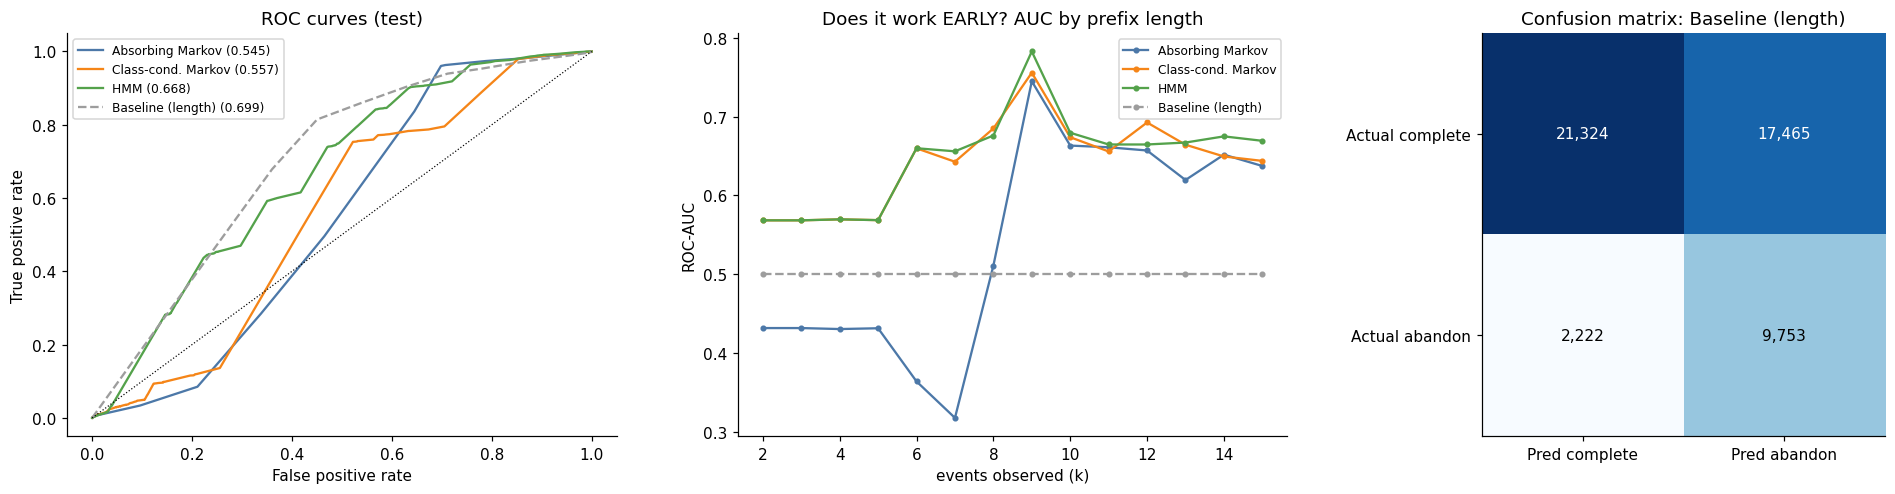

In [11]:
colors = {"Absorbing Markov": "#4C78A8", "Class-cond. Markov": "#F58518", "HMM": "#54A24B", "Baseline (length)": "#9D9D9D"}
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))

# (a) ROC
for m in MODELS:
    fpr, tpr, _ = roc_curve(test_s["y"], test_s[m])
    ax[0].plot(fpr, tpr, label=f"{m} ({results.loc[m, 'ROC-AUC']:.3f})", color=colors[m], ls="--" if "Base" in m else "-")
ax[0].plot([0, 1], [0, 1], "k:", lw=0.8)
ax[0].set(title="ROC curves (test)", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend(fontsize=8)

# (b) AUC by prefix length
for m in MODELS:
    aucs = {}
    for k, g in test_s.groupby("k"):
        if k <= 15 and g["y"].nunique() == 2 and len(g) >= 50:
            aucs[k] = roc_auc_score(g["y"], g[m])
    ax[1].plot(list(aucs), list(aucs.values()), marker="o", ms=3, label=m, color=colors[m], ls="--" if "Base" in m else "-")
ax[1].set(title="Does it work EARLY? AUC by prefix length", xlabel="events observed (k)", ylabel="ROC-AUC"); ax[1].legend(fontsize=8)

# (c) Confusion matrix, best model
best = results["ROC-AUC"].idxmax()
cm = confusion_matrix(test_s["y"], (test_s[best] >= thr[best]).astype(int))
ax[2].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[2].text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
ax[2].set(title=f"Confusion matrix: {best}", xticks=[0, 1], yticks=[0, 1],
          xticklabels=["Pred complete", "Pred abandon"], yticklabels=["Actual complete", "Actual abandon"])
plt.tight_layout(); plt.show()

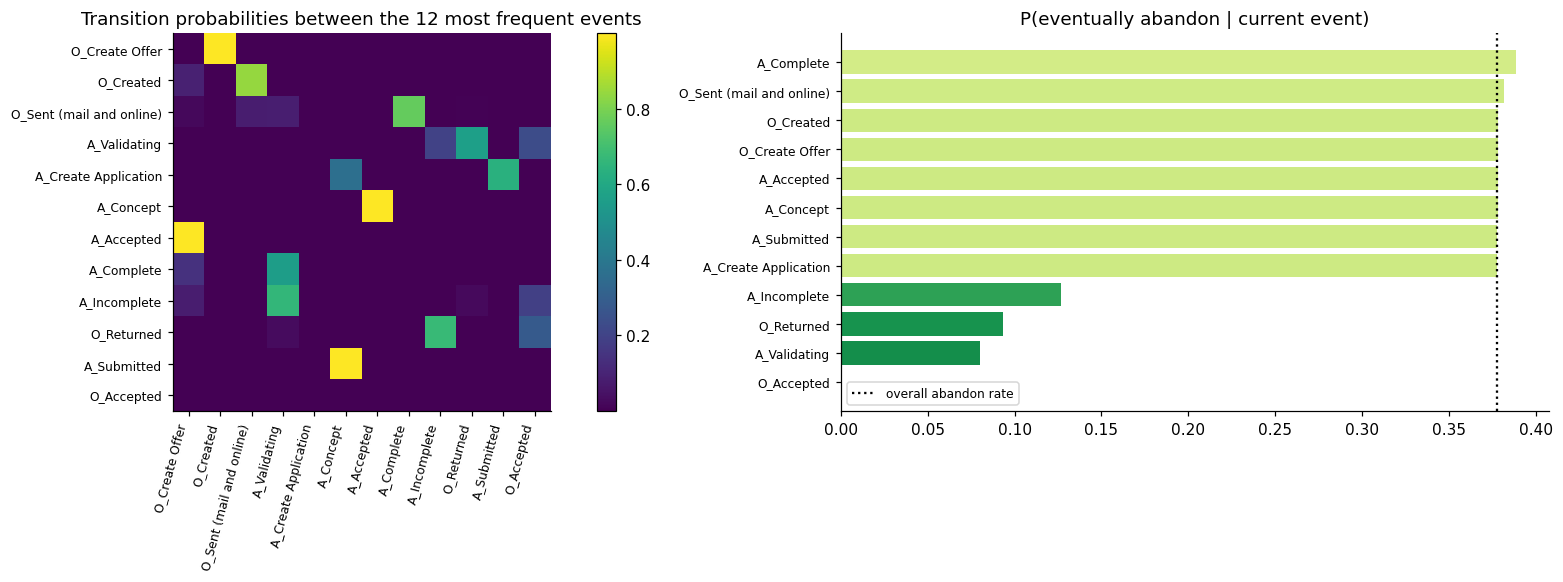

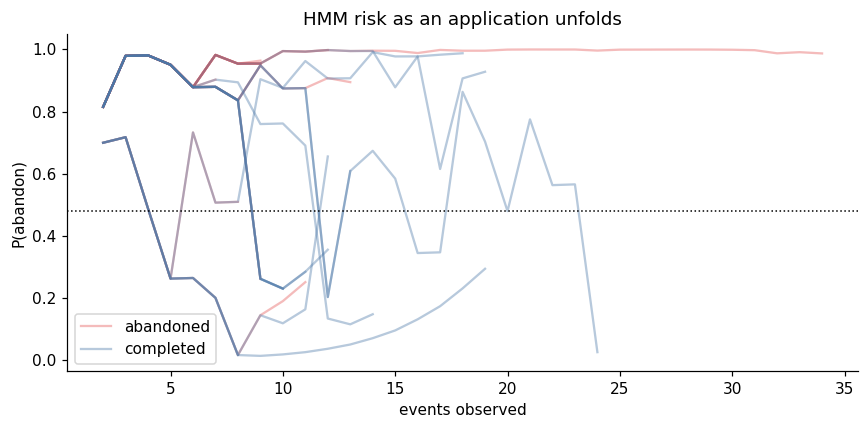

In [12]:
# (d) Markov structure: transition heatmap + which states are risky
top = [vocab[e] for e, _ in Counter(e for s in train["seq"] for e in s).most_common(12)]
sub = P_abs[np.ix_(top, top)]
names = [inv[i] for i in top]
fig, ax = plt.subplots(1, 2, figsize=(17, 5.4), gridspec_kw={"width_ratios": [1.3, 1]})
im = ax[0].imshow(sub, cmap="viridis"); plt.colorbar(im, ax=ax[0], fraction=0.046)
ax[0].set_xticks(range(len(top))); ax[0].set_yticks(range(len(top)))
ax[0].set_xticklabels(names, rotation=75, ha="right", fontsize=8); ax[0].set_yticklabels(names, fontsize=8)
ax[0].set_title("Transition probabilities between the 12 most frequent events")

order = np.argsort(p_ev[top])
ax[1].barh([names[i] for i in order], p_ev[top][order], color=plt.cm.RdYlGn_r(p_ev[top][order]))
ax[1].axvline(train["y"].mean(), color="k", ls=":", label="overall abandon rate"); ax[1].legend(fontsize=8)
ax[1].set_title("P(eventually abandon | current event)"); ax[1].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

# (e) Risk trajectories (HMM) for sample test cases
fig, ax = plt.subplots(figsize=(8, 4))
for y_, col, lab in [(1, "#E45756", "abandoned"), (0, "#4C78A8", "completed")]:
    ids = test_s[(test_s["y"] == y_)].groupby("case").size().loc[lambda s: s >= 6].index[:12]
    for j, cid in enumerate(ids):
        g = test_s[test_s["case"] == cid]
        ax.plot(g["k"], g["HMM"], color=col, alpha=0.4, label=lab if j == 0 else None)
ax.axhline(thr["HMM"], color="k", ls=":", lw=1); ax.set(title="HMM risk as an application unfolds", xlabel="events observed", ylabel="P(abandon)"); ax.legend()
plt.tight_layout(); plt.show()

## 10. Conclusion

In [13]:
from IPython.display import Markdown, display
bm = results["ROC-AUC"].idxmax()
base = results.loc["Baseline (length)", "ROC-AUC"]
lift = results.loc[bm, "ROC-AUC"] - base
prefix_txt = "**SYNTHETIC DEMO DATA, these numbers are not research findings.**\n\n" if USING_SYNTHETIC else ""
display(Markdown(f"""
{prefix_txt}### Summary
- **Task:** predict whether a loan application ends in cancellation using only the events seen so far (at least {GAP} steps before the end).
- **Best model:** **{bm}**, ROC-AUC **{results.loc[bm,'ROC-AUC']:.3f}**, PR-AUC {results.loc[bm,'PR-AUC']:.3f}, accuracy {results.loc[bm,'Accuracy']:.3f}, F1 {results.loc[bm,'F1']:.3f} on a chronological hold-out set.
- **Beats the trivial baseline?** The length-only baseline reaches AUC {base:.3f}, so the sequence models add **{lift:+.3f}** AUC.
- **Markov structure:** the absorbing chain pinpoints which events are risky states (see the heatmap and bar chart), which is easy to explain to stakeholders.
- **HMMs vs. chains:** compare the HMM and class-conditional rows above. A gain for the HMM suggests hidden customer "engagement modes" beyond the last event.

### Limitations
1. `A_Cancelled` mixes customer and bank-initiated cancellations, so it is a **noisy proxy** for customer drop-out.
2. Event timing (hours to days) is ignored; the models see order only. Adding dwell-time buckets would be the natural extension.
3. Prefixes from long cases are over-represented in pooled metrics; the AUC-by-length plot is the fairer view.
4. First-order Markov models forget history. Try second-order states or more HMM states if the data supports it.
5. Applying this to **mobile-app screens** needs app clickstream data. The method transfers; the fitted numbers do not.

### Next steps
Calibrate probabilities (isotonic), add time-bucketed states, test second-order chains, and evaluate cost-sensitive thresholds.
"""))


### Summary
- **Task:** predict whether a loan application ends in cancellation using only the events seen so far (at least 2 steps before the end).
- **Best model:** **Baseline (length)**, ROC-AUC **0.699**, PR-AUC 0.353, accuracy 0.612, F1 0.498 on a chronological hold-out set.
- **Beats the trivial baseline?** The length-only baseline reaches AUC 0.699, so the sequence models add **+0.000** AUC.
- **Markov structure:** the absorbing chain pinpoints which events are risky states (see the heatmap and bar chart), which is easy to explain to stakeholders.
- **HMMs vs. chains:** compare the HMM and class-conditional rows above. A gain for the HMM suggests hidden customer "engagement modes" beyond the last event.

### Limitations
1. `A_Cancelled` mixes customer and bank-initiated cancellations, so it is a **noisy proxy** for customer drop-out.
2. Event timing (hours to days) is ignored; the models see order only. Adding dwell-time buckets would be the natural extension.
3. Prefixes from long cases are over-represented in pooled metrics; the AUC-by-length plot is the fairer view.
4. First-order Markov models forget history. Try second-order states or more HMM states if the data supports it.
5. Applying this to **mobile-app screens** needs app clickstream data. The method transfers; the fitted numbers do not.

### Next steps
Calibrate probabilities (isotonic), add time-bucketed states, test second-order chains, and evaluate cost-sensitive thresholds.
